# 02. Модельная таблица и временные границы

Собираем одинаковые строки для вариантов без погоды и с погодой.
Исходные таблицы не меняются. Преобразования времени детерминированы;
заполнение пропусков, кодирование категорий и обучение не выполняются.
Идентификаторы и будущие исходы используются только для проверки связей
и отдельной маски зазора. Они не попадают в реестр предикторов.
Историческая доступность признаков условна; test ранее просматривался.


In [1]:
from pathlib import Path
import hashlib, json
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd(); OUT=ROOT/'research/weather-model-comparison'
DEST=OUT/'data/model_table_v1'; DEST.mkdir(parents=True,exist_ok=True)
def sha(p):
    with p.open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()
source=ROOT/'europe/data/analytical/06_05_cases_excluded.parquet'
readiness=json.loads((OUT/'reports/01_readiness_manifest.json').read_text(encoding='utf8'))
assert sha(source)==readiness['source_input_sha256']
N=readiness['rows']; assert N==6331485
WEATHER=['wind_speed_kt_model','wind_gust_kt_model','wind_direction_deg_model',
'wind_variable_from_deg_model','wind_variable_to_deg_model','visibility_m_model',
'cloud_ceiling_ft_model','lowest_known_cloud_base_ft_model','vertical_visibility_ft_model',
'temperature_c_model','dewpoint_c_model','qnh_hpa_model','wind_variable_model',
'wind_calm_model','gust_group_reported_model','visibility_relation_model',
'visibility_ndv_model','cavok_model','cloud_ceiling_relation_model',
'cloud_ceiling_status_model','cloud_amount_unavailable_model','cloud_type_unavailable_model',
'cumulonimbus_reported_model','towering_cumulus_reported_model',
'present_weather_tokens_model','present_weather_status_model']
BASE=['airport','C40_CROSS_LAT','C40_CROSS_LON','typecode',
      'hour_utc_sin','hour_utc_cos','day_of_year_sin','day_of_year_cos']
assert len(WEATHER)==26
VALID=pd.Timestamp('2022-01-01',tz='UTC'); TEST=pd.Timestamp('2023-01-01',tz='UTC')


## 1. Проверки событий и маска зазора

Читаем исходную базу порциями. Проверяем непустые списки попыток,
C40 перед первой попыткой, составной ключ и прокси события.
Уникальность хешей ключей является достаточной проверкой уникальности
самих ключей; при совпадении хешей выполнение останавливается для
проверки исходных ключей. Повторный flight_id сам по себе не считается утечкой.
Зазор 24 часа применяется перед следующей частью; пересечение исхода
имеет приоритет. Основная временная карта сохраняет все строки.


In [2]:
pieces=[]; key_hashes=[]; event_hashes=[]; offset=0; split_counts=Counter()
cols=['flight_id','icao24','airport','landing_time','attempt_times','GoA',
      'C40_CROSS_TIME','C40_CROSS_LAT','C40_CROSS_LON','typecode']
reader=pq.ParquetFile(source)
for batch in reader.iter_batches(batch_size=200000,columns=cols):
    f=batch.to_pandas(ignore_metadata=True)
    assert f.attempt_times.map(len).gt(0).all()
    first=pd.to_datetime(f.attempt_times.map(min),utc=True)
    last=pd.to_datetime(f.attempt_times.map(max),utc=True)
    t=pd.to_datetime(f.C40_CROSS_TIME,utc=True)
    assert t.notna().all() and (t<first).all() and t.dt.year.between(2019,2023).all()
    assert f[['flight_id','icao24','airport','landing_time']].notna().all().all()
    key_hashes.append(pd.util.hash_pandas_object(f[['flight_id','icao24','airport','landing_time']],index=False).to_numpy())
    event_hashes.append(pd.util.hash_pandas_object(pd.DataFrame({'icao24':f.icao24,'airport':f.airport,'first':first}),index=False).to_numpy())
    parts=np.where(t<VALID,'train',np.where(t<TEST,'validation','test'))
    outcome=pd.concat([pd.to_datetime(f.landing_time,utc=True),last],axis=1).max(axis=1)
    purge=((parts=='train')&outcome.ge(VALID))|((parts=='validation')&outcome.ge(TEST))
    gap=((parts=='train')&t.ge(VALID-pd.Timedelta(hours=24)))|((parts=='validation')&t.ge(TEST-pd.Timedelta(hours=24)))
    status=np.where(purge,'purge_outcome_boundary',np.where(gap,'embargo','retained'))
    for p,g,y in zip(parts,status,f.GoA): split_counts[(p,g,bool(y))]+=1
    q=f[['airport','GoA','C40_CROSS_TIME','C40_CROSS_LAT','C40_CROSS_LON','typecode']].copy()
    q['source_row']=np.arange(offset,offset+len(f),dtype=np.int64)
    q['temporal_split']=parts; q['gap_status']=status
    pieces.append(q); offset+=len(f)
del reader
assert offset==N
for name,arrays in [('composite_key',key_hashes),('event_proxy',event_hashes)]:
    values=np.concatenate(arrays)
    assert len(np.unique(values))==N, f'{name}: inspect duplicate keys or hash collisions'
del key_hashes,event_hashes,values
original=pd.concat(pieces,ignore_index=True); del pieces
assert original.GoA.sum()==18349
boundaries=pd.DataFrame([{'temporal_split':p,'gap_status':g,'GoA':y,'rows':n} for (p,g,y),n in split_counts.items()])
boundaries.to_csv(OUT/'reports/02_boundary_counts.csv',index=False)
display(boundaries)
assert boundaries.loc[boundaries.gap_status.eq('embargo'),'rows'].sum()==3567
assert boundaries.loc[boundaries.gap_status.eq('purge_outcome_boundary'),'rows'].sum()==1


,temporal_split,gap_status,GoA,rows
0,train,retained,False,4149875
1,train,retained,True,11618
2,train,embargo,False,3559
3,train,embargo,True,8
4,validation,retained,False,1614863
5,validation,retained,True,4984
6,validation,purge_outcome_boundary,False,1
7,test,retained,False,544838
8,test,retained,True,1739


## 2. Сборка 93 файлов модельной таблицы

Каждый файл присоединяется по source_row с проверкой one-to-one и хешей.
Годовая фаза использует фактическое число дней соответствующего года;
часовая фаза включает минуты, секунды и доли секунды UTC.
Сохраняем исходные пропуски и значения 26 погодных копий. Модельная
таблица содержит аудитные колонки, но предикторы заданы отдельным реестром.


In [3]:
seen=np.zeros(N,dtype=bool); files=[]; summaries=[]; registry=None
checks={x['file']:x for x in readiness['files']}
weather=ROOT/'europe/weather/data/final_c40_weather_v1'
mapping=ROOT/'europe/weather/data/temporal_split_v1'
for path in sorted(weather.glob('*.parquet')):
    entry=checks[path.name]
    assert sha(path)==entry['weather_sha256']
    assert sha(mapping/path.name)==entry['mapping_sha256']
    schema=pq.read_schema(path)
    assert set(x for x in schema.names if x.endswith('_model'))==set(WEATHER)
    w=pd.read_parquet(path,columns=['source_row','airport','GoA','C40_CROSS_TIME','weather_core_usable']+WEATHER)
    ids=w.source_row.to_numpy(dtype=np.int64)
    assert ((ids>=0)&(ids<N)).all() and len(np.unique(ids))==len(ids) and not seen[ids].any()
    f=original.iloc[ids].reset_index(drop=True)
    assert np.array_equal(f.source_row,ids)
    for col in ['airport','GoA','C40_CROSS_TIME']: assert f[col].equals(w[col])
    m=pd.read_parquet(mapping/path.name,columns=['source_row','temporal_split'])
    check=f[['source_row','temporal_split']].merge(m,on='source_row',validate='one_to_one',suffixes=('_source','_map'))
    assert check.temporal_split_source.equals(check.temporal_split_map)
    joined=f.merge(w.drop(columns=['airport','GoA','C40_CROSS_TIME']),on='source_row',validate='one_to_one')
    t=pd.to_datetime(joined.C40_CROSS_TIME,utc=True)
    hour=(t-t.dt.normalize()).dt.total_seconds()/86400
    annual=(t.dt.dayofyear-1+hour)/np.where(t.dt.is_leap_year,366,365)
    joined['hour_utc_sin']=np.sin(2*np.pi*hour); joined['hour_utc_cos']=np.cos(2*np.pi*hour)
    joined['day_of_year_sin']=np.sin(2*np.pi*annual); joined['day_of_year_cos']=np.cos(2*np.pi*annual)
    joined['typecode']=joined.typecode.mask(joined.typecode.eq(''))
    assert np.isfinite(joined[['C40_CROSS_LAT','C40_CROSS_LON']].to_numpy()).all()
    assert joined.C40_CROSS_LAT.between(-90,90).all() and joined.C40_CROSS_LON.between(-180,180).all()
    for col in WEATHER:
        assert joined[col].equals(w[col]), col
        if pd.api.types.is_numeric_dtype(joined[col]) and not pd.api.types.is_bool_dtype(joined[col]):
            assert np.isfinite(joined[col].dropna().to_numpy()).all()
    if registry is None:
        registry=[{'field':c,'block':'nonweather' if c in BASE else 'weather',
                   'kind':'categorical' if c in ['airport','typecode'] or (c in WEATHER and str(schema.field(c).type)=='large_string') else ('boolean' if c in WEATHER and str(schema.field(c).type)=='bool' else 'numeric'),
                   'missing_policy':'retain; transformation fit on train only'} for c in BASE+WEATHER]
    target=DEST/path.name; joined.to_parquet(target,index=False)
    files.append({'file':path.name,'rows':len(joined),'sha256':sha(target)})
    for (part,status),g in joined.groupby(['temporal_split','gap_status']):
        summaries.append({'temporal_split':part,'gap_status':status,'rows':len(g),'GoA':int(g.GoA.sum()),'weather_usable':int(g.weather_core_usable.sum())})
    seen[ids]=True
assert seen.all() and len(files)==93
summary=pd.DataFrame(summaries).groupby(['temporal_split','gap_status'],as_index=False).sum()
assert summary.rows.sum()==N and summary.GoA.sum()==18349
summary.to_csv(OUT/'reports/02_model_table_counts.csv',index=False)
pd.DataFrame(registry).to_csv(OUT/'reports/02_feature_registry.csv',index=False)
manifest={'verified':True,'rows':N,'GoA':18349,'source_input_sha256':readiness['source_input_sha256'],
'protocol_sha256':sha(OUT/'protocol.md'),'files':files,'baseline_features':BASE,'weather_features':WEATHER,
'core_features':[c for c in BASE if c!='typecode'],'composite_key_unique':True,'event_proxy_unique':True,
'weather_values_preserved':True,'training_executed':False,'transformations_fitted':False}
(OUT/'reports/02_model_table_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n',encoding='utf8')
display(pd.DataFrame(registry)); display(summary)


,field,block,kind,missing_policy
0,airport,nonweather,categorical,retain; transformation fit on train only
1,C40_CROSS_LAT,nonweather,numeric,retain; transformation fit on train only
2,C40_CROSS_LON,nonweather,numeric,retain; transformation fit on train only
3,typecode,nonweather,categorical,retain; transformation fit on train only
4,hour_utc_sin,nonweather,numeric,retain; transformation fit on train only
5,hour_utc_cos,nonweather,numeric,retain; transformation fit on train only
6,day_of_year_sin,nonweather,numeric,retain; transformation fit on train only
7,day_of_year_cos,nonweather,numeric,retain; transformation fit on train only
8,wind_speed_kt_model,weather,numeric,retain; transformation fit on train only
9,wind_gust_kt_model,weather,numeric,retain; transformation fit on train only


,temporal_split,gap_status,rows,GoA,weather_usable
0,test,retained,546577,1739,546038
1,train,embargo,3567,8,3567
2,train,retained,4161493,11618,4155270
3,validation,purge_outcome_boundary,1,0,1
4,validation,retained,1619847,4984,1617710


## 3. Объемы основной и дополнительной выборок

Основная выборка сохраняет все строки. Дополнительная маска оставляет
только retained; непогодный и погодный варианты используют одинаковую маску.
Уникальность прокси исключает его повторение между частями, но не доказывает
независимость разных рейсов или достоверность исходного детектора GoA.


,main_rows,main_GoA,gap_rows,gap_GoA
temporal_split,,,,
train,4165060,11626,4161493,11618
validation,1619848,4984,1619847,4984
test,546577,1739,546577,1739


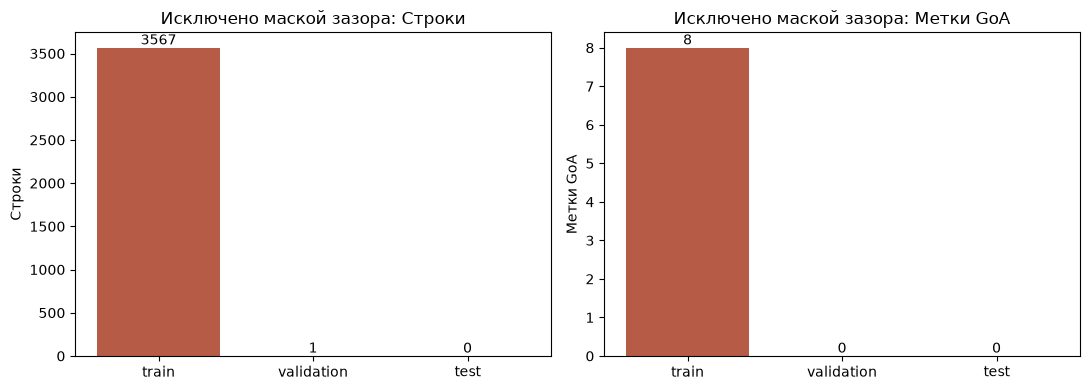

Модельная таблица проверена. Fit и обучение не выполнялись.


In [4]:
main=summary.groupby('temporal_split')[['rows','GoA']].sum().reindex(['train','validation','test'])
gap=summary[summary.gap_status.eq('retained')].set_index('temporal_split').reindex(main.index)
comparison=main.rename(columns={'rows':'main_rows','GoA':'main_GoA'}).join(gap[['rows','GoA']].rename(columns={'rows':'gap_rows','GoA':'gap_GoA'}))
comparison.to_csv(OUT/'reports/02_split_comparison.csv')
display(comparison)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,col,title in [(axes[0],'rows','Строки'),(axes[1],'GoA','Метки GoA')]:
    lost=main[col]-gap[col]
    ax.bar(main.index,lost,color='#b65b45'); ax.set_title('Исключено маской зазора: '+title)
    ax.set_ylabel(title)
    for i,value in enumerate(lost): ax.text(i,value,str(int(value)),ha='center',va='bottom')
fig.tight_layout()
for ext in ['png','svg']: fig.savefig(OUT/f'figures/02_boundary_exclusions.{ext}',dpi=160,bbox_inches='tight')
plt.show()
print('Модельная таблица проверена. Fit и обучение не выполнялись.')


## Точка продолжения

Подготовлены таблица и строгий реестр признаков. Следующее — реализовать
конвейер преобразований и оценки; запуск fit требует отдельного разрешения.
Результатов качества моделей и подтверждения эксплуатационной пригодности нет.
